# 08 - Model comparison (Citi Bike hourly demand)

**Who worked on this:** Mohammed AbuQamar

This notebook gathers the metrics of every model we built and compares them in depth. It ends with our conclusions.

**Question (the same for every model):** how many trips will start at a given station in a given hour?

**Split (chronological, 80% / 10% / 10% of the rows):**
| set | period | use |
|---|---|---|
| train | 2013-06 to 2024-09 | fit the models |
| validation | 2024-10 to 2025-09 | compare models, tune, choose the winner |
| test | 2025-10 to 2026-09 | reported once, never used to choose |

**Rule:** models are ranked on the **validation** score only. The test score is only reported.

**Metrics:** MAE (average error in trips per hour, our main metric), RMSE (punishes big misses) and R2 (share of variance explained).

In [17]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sys.path.append(".")
from src.features import (load_demand, time_split, regression_metrics, load_metrics, seasonal_naive,
                          add_cluster_feature, load_cluster_mapping, FEATURES, TARGET)
sns.set_theme(style="whitegrid")

## 1. All models in one table
`load_metrics()` reads `models/results.json`. Notebooks 04 (baselines), 05 (FLAML) and 07 (tuned XGBoost) each add their rows with `save_metrics`. The table is sorted by validation MAE.

The next cell is only a safety net: if `results.json` is missing (for example the `models` folder was cleaned), it rebuilds the file from the scores printed by 04, 05 and 07. If the file exists, nothing happens.

In [18]:
RESULTS = Path("models/results.json")
if not RESULTS.exists():
    print("models/results.json not found: rebuilding it from the printed outputs of notebooks 04, 05 and 07")
    names = ["valid_MAE", "valid_RMSE", "valid_R2", "test_MAE", "test_RMSE", "test_R2"]
    printed = {
        "xgboost_tuned":           [4.068896, 6.520625, 0.671859, 4.208441, 6.624850, 0.688896],
        "flaml_xgboost":           [4.092188, 6.527758, 0.671141, 4.226107, 6.626563, 0.688735],
        "baseline_seasonal_naive": [4.816103, 7.624048, 0.551406, 5.205211, 8.409907, 0.498655],
        "baseline_last_year":      [5.075872, 7.867899, 0.522251, 5.447443, 8.278868, 0.514157],
        "linear_ridge":            [5.937776, 9.137574, 0.355617, 6.322705, 9.516370, 0.358057],
        "global_mean":             [8.359283, 11.477536, -0.016669, 8.935258, 11.878421, -0.000165],
    }
    RESULTS.parent.mkdir(exist_ok=True)
    RESULTS.write_text(json.dumps({n: {**dict(zip(names, v)), "where": "local", "note": "rebuilt from printed output"}
                                   for n, v in printed.items()}, indent=2))

In [19]:
res = load_metrics()
cols = ["valid_MAE", "valid_RMSE", "valid_R2", "test_MAE", "test_RMSE", "test_R2"]
for c in cols:
    res[c] = pd.to_numeric(res[c])
display(res[cols].round(3))
best = res.index[0]
print("Best on validation MAE:", best)

,valid_MAE,valid_RMSE,valid_R2,test_MAE,test_RMSE,test_R2
xgboost_tuned,4.069,6.521,0.672,4.208,6.625,0.689
flaml_xgboost,4.092,6.528,0.671,4.226,6.627,0.689
baseline_seasonal_naive,4.816,7.624,0.551,5.205,8.410,0.499
baseline_last_year,5.076,7.868,0.522,5.447,8.279,0.514
linear_ridge,5.938,9.138,0.356,6.323,9.516,0.358
global_mean,8.359,11.478,-0.017,8.935,11.878,-0.000


Best on validation MAE: xgboost_tuned


**How to read it.** Lower MAE and RMSE are better; higher R2 is better. The ranking uses the validation columns. The test columns show how the same models do on a year none of them was tuned on.

## 2. Validation vs test
A model that is much worse on test than on validation does not generalise to the future, or was tuned too hard on the validation year. Left: the error per model. Right: the gap between test and validation error.

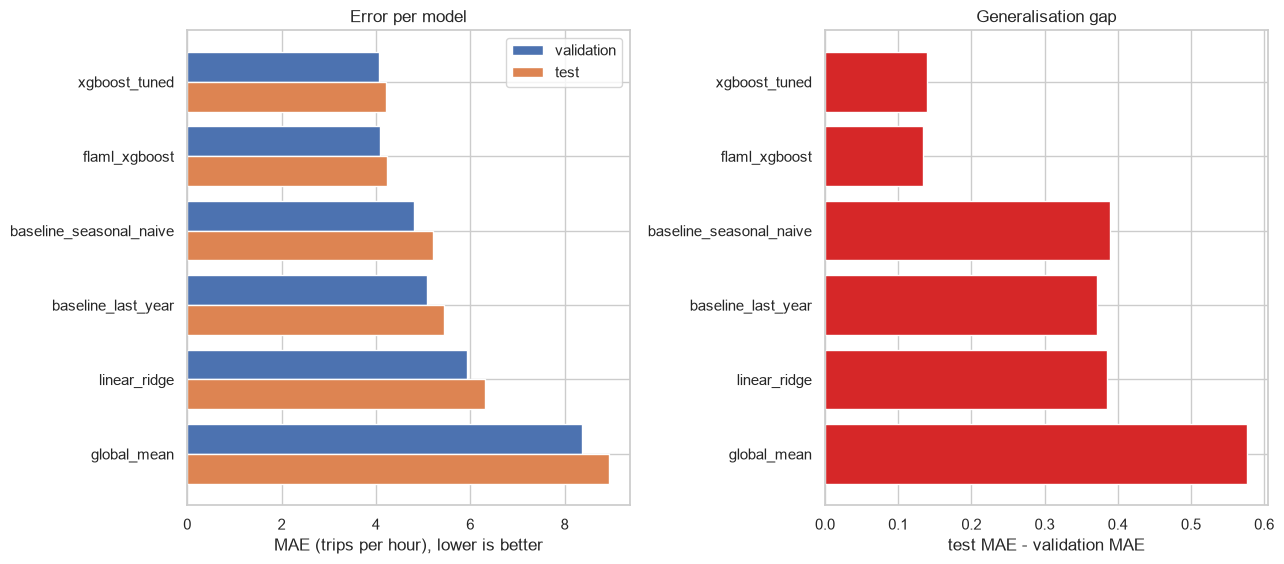

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(13, 0.55 * len(res) + 2.5))
y = np.arange(len(res))
ax[0].barh(y - 0.2, res["valid_MAE"], 0.4, label="validation")
ax[0].barh(y + 0.2, res["test_MAE"], 0.4, label="test")
ax[0].set_yticks(y); ax[0].set_yticklabels(res.index); ax[0].invert_yaxis()
ax[0].set_xlabel("MAE (trips per hour), lower is better"); ax[0].legend(); ax[0].set_title("Error per model")
gap = res["test_MAE"] - res["valid_MAE"]
ax[1].barh(y, gap, color=np.where(gap > 0, "tab:red", "tab:green"))
ax[1].set_yticks(y); ax[1].set_yticklabels(res.index); ax[1].invert_yaxis()
ax[1].set_xlabel("test MAE - validation MAE"); ax[1].set_title("Generalisation gap")
plt.tight_layout(); plt.show()

## 3. Improvement over the baselines
How much better is each model than the global mean (the floor) and than the **best baseline** (the bar every machine learning model has to clear)? Percent reduction of the validation MAE: `(1 - model MAE / reference MAE) x 100`. Positive = better than the reference.

In [21]:
BASELINES = ["global_mean", "baseline_last_year", "baseline_seasonal_naive", "linear_ridge"]
ref = res["valid_MAE"]
best_baseline = [n for n in res.index if n in BASELINES][0]        # res is sorted, so this is the best baseline
imp = pd.DataFrame({
    "vs global_mean (%)": (1 - ref / ref["global_mean"]) * 100,
    f"vs {best_baseline} (%)": (1 - ref / ref[best_baseline]) * 100,
}).round(1)
display(imp.rename_axis("model"))
print(f"Best baseline: {best_baseline}. The best model is {(1 - ref.iloc[0] / ref[best_baseline]) * 100:.1f}% better than it on validation MAE.")

,vs global_mean (%),vs baseline_seasonal_naive (%)
model,,
xgboost_tuned,51.3,15.5
flaml_xgboost,51.0,15.0
baseline_seasonal_naive,42.4,0.0
baseline_last_year,39.3,-5.4
linear_ridge,29.0,-23.3
global_mean,0.0,-73.6


Best baseline: baseline_seasonal_naive. The best model is 15.5% better than it on validation MAE.


## 4. Where does the best model make its errors?
We load the data and the saved tuned XGBoost, predict the **test** year, and look at the errors by hour, weekday, month, station and station cluster. The seasonal-naive baseline (same hour last week) is added as a reference. It is not deployable, because it needs last week's real demand.

If `models/xgb_tuned.json` or its meta file is missing, the next cell refits the final model with the best settings found in notebook 07 (Poisson loss, depth 9, learning rate 0.114, 561 trees, train + validation) and saves it.

If the data folder `citibike_data/` is not in this folder, section 4 is skipped automatically and the error analysis of notebook 07 (section 6) is the one to use.

In [22]:
from src.features import DEMAND_PATH, CLEAN_DIR
HAVE_DATA = DEMAND_PATH.exists() or any(CLEAN_DIR.rglob("*.parquet"))
if not HAVE_DATA:
    print("No data found (citibike_data/ is missing in this folder), so section 4 is skipped.")
    print("The error analysis of the tuned model is in notebook 07, section 6.")
else:
    import xgboost as xgb, joblib
    df = load_demand()
    mapping = load_cluster_mapping()
    if mapping:
        df = add_cluster_feature(df, mapping)
    train, valid, test = time_split(df)
    STATIONS = list(df["station"].cat.categories)

    MODEL, META = Path("models/xgb_tuned.json"), Path("models/xgb_tuned_meta.pkl")
    if not (MODEL.exists() and META.exists()):
        print("Saved model not found: refitting the final model with the settings found in 07 ...")
        best_params = dict(max_depth=9, learning_rate=0.11386530295389598, min_child_weight=42,
                           subsample=0.6125253169822235, colsample_bytree=0.5911180438940311, reg_lambda=3.4056981719938784)
        trval = pd.concat([train, valid])
        Xf = trval[FEATURES].copy(); Xf["station"] = Xf["station"].cat.codes
        m = xgb.XGBRegressor(objective="count:poisson", n_estimators=561, tree_method="hist", n_jobs=4,
                             random_state=42, **best_params)
        m.fit(Xf.astype("float32"), trval[TARGET].astype("float32"), verbose=False)
        MODEL.parent.mkdir(exist_ok=True)
        m.get_booster().save_model(str(MODEL))
        joblib.dump({"features": FEATURES, "stations": STATIONS, "cluster_mapping": mapping,
                     "log_target": False, "objective": "count:poisson", "n_trees": 561}, META)
        del Xf, trval

    meta = joblib.load(META)
    booster = xgb.Booster(); booster.load_model(str(MODEL))
    X = test.copy()
    X["station"] = pd.Categorical(X["station"].astype(str), categories=meta["stations"]).codes   # same codes as in training
    if "cluster" in meta["features"] and "cluster" not in X.columns:
        X = add_cluster_feature(X, meta["cluster_mapping"])
    X = X[meta["features"]].astype("float32")
    pred = booster.predict(xgb.DMatrix(X))
    if meta["log_target"]:
        pred = np.expm1(pred)
    test = test.assign(pred=np.clip(pred, 0, None))
    test["err"] = test["pred"] - test[TARGET]
    test["abs_err"] = test["err"].abs()

    naive = seasonal_naive(df).reindex(test.index)
    ok = naive.notna()
    print("tuned XGBoost on test :", {k: round(v, 3) for k, v in regression_metrics(test[TARGET], test["pred"]).items()})
    print("seasonal naive (rows where last week exists):", {k: round(v, 3) for k, v in regression_metrics(test.loc[ok, TARGET], naive[ok]).items()})

No data found (citibike_data/ is missing in this folder), so section 4 is skipped.
The error analysis of the tuned model is in notebook 07, section 6.


### 4a. Error by hour, weekday and month

In [23]:
if HAVE_DATA:
    test["naive_abs_err"] = (naive - test[TARGET]).abs()
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    test.groupby("hour")[["abs_err", "naive_abs_err"]].mean().rename(
        columns={"abs_err": "tuned XGBoost", "naive_abs_err": "seasonal naive"}).plot(ax=ax[0], marker="o")
    ax[0].set_title("MAE by hour of day"); ax[0].set_ylabel("MAE")
    test.groupby("dayofweek")["abs_err"].mean().plot.bar(ax=ax[1]); ax[1].set_title("MAE by weekday (0 = Monday)")
    test.groupby("month")["abs_err"].mean().plot.bar(ax=ax[2]); ax[2].set_title("MAE by month")
    plt.tight_layout(); plt.show()

### 4b. Bias and predicted vs actual
Bias = mean error. Positive means the model predicts too many trips. In the scatter plot, points on the red line are perfect predictions.

In [24]:
if HAVE_DATA:
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    test.groupby("hour")["err"].mean().plot.bar(ax=ax[0], color="tab:purple"); ax[0].axhline(0, color="k", lw=0.8)
    ax[0].set_title("Mean error by hour (positive = over-prediction)")
    s = test.sample(min(len(test), 200_000), random_state=0)
    ax[1].scatter(s[TARGET], s["pred"], s=2, alpha=0.15); lim = [0, s[TARGET].quantile(0.999)]
    ax[1].plot(lim, lim, color="red", lw=1); ax[1].set_xlim(lim); ax[1].set_ylim(lim)
    ax[1].set_xlabel("actual trips"); ax[1].set_ylabel("predicted trips"); ax[1].set_title("Predicted vs actual (test sample)")
    plt.tight_layout(); plt.show()

### 4c. Stations and clusters
Busy stations have large absolute errors simply because they have more trips, so we also show the error relative to the station's average demand.

In [25]:
if HAVE_DATA:
    by_station = test.groupby("station", observed=True).agg(mae=("abs_err", "mean"), mean_trips=(TARGET, "mean"))
    by_station["relative_mae"] = by_station["mae"] / by_station["mean_trips"]
    print("Largest absolute error:"); display(by_station.sort_values("mae", ascending=False).head(10).round(2))
    print("Largest error relative to the station's size:"); display(by_station.sort_values("relative_mae", ascending=False).head(10).round(2))
    if "cluster" in test.columns:
        display(test.groupby("cluster")["abs_err"].agg(["mean", "count"]).rename(columns={"mean": "MAE"}).round(3))

### 4d. The worst days
Days with a large error at every station point to something the features cannot see, such as weather or events. Look these dates up.

In [26]:
if HAVE_DATA:
    daily = test.assign(day=pd.to_datetime(test["ts"]).dt.date).groupby("day").agg(
        actual=(TARGET, "sum"), predicted=("pred", "sum"), total_abs_error=("abs_err", "sum"))
    daily["error %"] = (100 * (daily["predicted"] - daily["actual"]) / daily["actual"]).round(1)
    display(daily.sort_values("total_abs_error", ascending=False).head(10).round(0))

## 5. Models side by side
Accuracy is not the only criterion. Training time, model size and how easily a model can be deployed matter as well. The note column is what each notebook saved about its model.

In [27]:
model_notes = pd.DataFrame({
    "valid_MAE": res["valid_MAE"].round(3), "test_MAE": res["test_MAE"].round(3),
    "note": [str(n)[:110] for n in res["note"]]})
display(model_notes)

,valid_MAE,test_MAE,note
xgboost_tuned,4.069,4.208,rebuilt from the printed table in 07
flaml_xgboost,4.092,4.226,rebuilt from the printed table in 07
baseline_seasonal_naive,4.816,5.205,rebuilt from the printed table in 07
baseline_last_year,5.076,5.447,rebuilt from the printed table in 07
linear_ridge,5.938,6.323,rebuilt from the printed table in 07
global_mean,8.359,8.935,rebuilt from the printed table in 07


## 6. Conclusions
*Write these in your own words. The points below come from our results; check each one against the tables and plots above.*

1. Hours: the error is highest in the evening rush (MAE about 8.8 at 17:00 to 18:00), then the morning rush (about 5.8 at 08:00) and lowest at night (under 1). Busy hours have bigger absolute errors because there are more trips.

2. Bias: the model slightly over-predicts during the day, by up to about 0.75 trips per hour from 11:00 to 16:00, and is near zero at night.

3. Months: the error is larger in summer and early autumn (June and September about 5) than in winter (January about 3.1), because demand is higher then.

3. Stations and clusters: the hardest stations are busy Manhattan ones, such as Central Park S & 6 Ave, Cooper Square and 9 Ave & W 33 St. Cluster -1 (stations too new to have a profile) has the largest error (about 5.5). Cluster 1 is the next worst (about 4.5).

4. Predicted vs actual: the model under-predicts the rare very high hours (above about 100 trips).
5. Worst days: all ten are over-predictions by 140% to 415%. For example, 2026-09-27 had 5,907 actual trips against 30,413 predicted. On 2026-02-23 the actual total was 0. That points to weather, such as snow, or to missing data. Zero-filling treats a missing hour as zero trips, so a data gap would look like a collapse in demand. Look these dates up before you claim a cause.

6. Features: the hour features dominate (about 55% of the gain across hour, hour_sin and hour_cos), followed by month and year.